# Volet B — Segmentation non supervisée des utilisateurs

Cette analyse compare K-Means, CAH et DBSCAN sur les préférences par genre. La matrice `data/processed/user_genre_matrix.csv` d’Asma est utilisée dès qu’elle est disponible. En attendant, une matrice dérivée de `ratings.csv` et `movies.csv` est produite dans `data/processed/user_genre_matrix_derived.csv` : chaque film noté répartit une unité entre ses genres, puis les contributions sont rapportées au nombre de films notés par utilisateur.

In [26]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'data' / 'raw' / 'movies.csv').exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Impossible de localiser data/raw/movies.csv.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import src.unsupervised as unsupervised
importlib.reload(unsupervised)

from src.unsupervised import (
    cluster_movies,
    compare_clusterings,
    evaluate_kmeans,
    fit_dbscan,
    load_user_genre_data,
    profile_segments,
)

user_genre_matrix, movies, ratings, matrix_source, fallback_path = load_user_genre_data(ROOT)
user_ids = user_genre_matrix['userId'].to_numpy()
genre_columns = [column for column in user_genre_matrix.columns if column != 'userId']
X_raw = user_genre_matrix[genre_columns].to_numpy(dtype=float)
X_scaled = StandardScaler().fit_transform(X_raw)

print(f'Source de la matrice : {matrix_source}')
print(f'Utilisateurs : {len(user_ids)} | Genres : {len(genre_columns)}')
if 'derived fallback' in matrix_source:
    print(f'Matrice de remplacement créée : {fallback_path.relative_to(ROOT)}')
print(f'Forme après StandardScaler : {X_scaled.shape}')

Source de la matrice : ratings.csv + movies.csv (derived fallback)
Utilisateurs : 610 | Genres : 19
Matrice de remplacement créée : data\processed\user_genre_matrix_derived.csv
Forme après StandardScaler : (610, 19)


## ACP — variance expliquée et projection en deux dimensions

La standardisation est appliquée avant l’ACP et les trois algorithmes.

Variance expliquée par composante : [0.2142 0.1894]
Variance cumulée en 2D : 40.4%


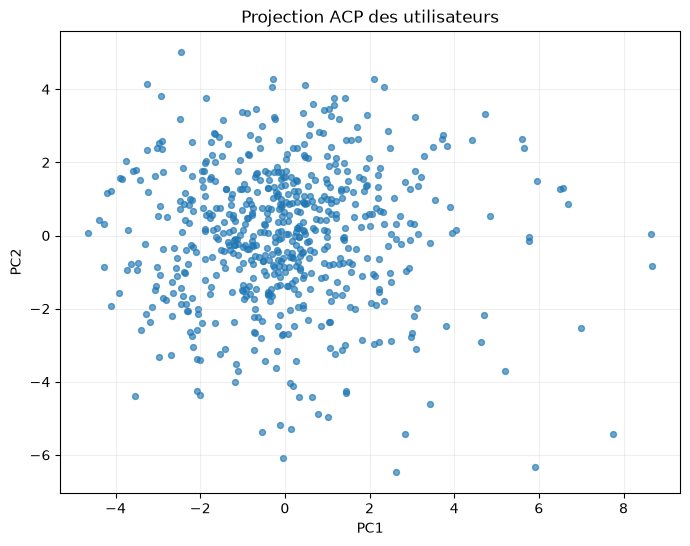

In [20]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print('Variance expliquée par composante :', np.round(pca.explained_variance_ratio_, 4))
print(f'Variance cumulée en 2D : {pca.explained_variance_ratio_.sum():.1%}')

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X_pca[:, 0], X_pca[:, 1], s=18, alpha=0.65)
ax.set(title='Projection ACP des utilisateurs', xlabel='PC1', ylabel='PC2')
ax.grid(alpha=0.2)
plt.show()

## K-Means — méthode du coude et silhouette

Le nombre de clusters retenu maximise la silhouette parmi les valeurs testées (2 à 10). La courbe d’inertie complète ce choix avec la méthode du coude.

k retenu : 2 (silhouette maximale dans la plage testée)


,k,inertia,silhouette
0,2,10132.096008,0.124772
1,3,9121.538903,0.121866
2,4,8450.623999,0.112713
3,5,8054.905504,0.106148
4,6,7694.749670,0.094108
5,7,7374.565835,0.092487
6,8,7087.252332,0.088666
7,9,6817.326615,0.101604
8,10,6534.085689,0.106244


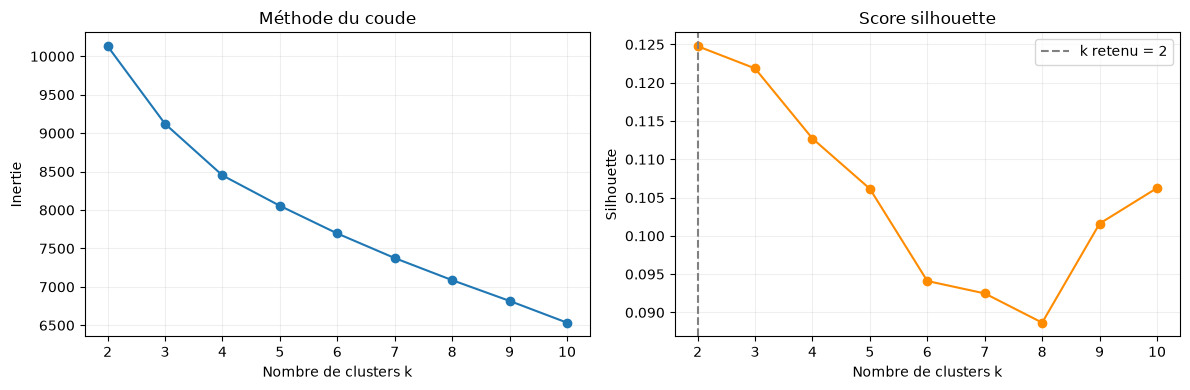

In [22]:
kmeans_scores, kmeans_model = evaluate_kmeans(X_scaled, max_k=10)
kmeans_labels = kmeans_model.labels_
best_k = kmeans_model.n_clusters
print(f'k retenu : {best_k} (silhouette maximale dans la plage testée)')
display(kmeans_scores)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(kmeans_scores['k'], kmeans_scores['inertia'], marker='o')
axes[0].set(title='Méthode du coude', xlabel='Nombre de clusters k', ylabel='Inertie')
axes[1].plot(kmeans_scores['k'], kmeans_scores['silhouette'], marker='o', color='darkorange')
axes[1].axvline(best_k, color='grey', linestyle='--', label=f'k retenu = {best_k}')
axes[1].set(title='Score silhouette', xlabel='Nombre de clusters k', ylabel='Silhouette')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## CAH et DBSCAN

La CAH utilise le lien de Ward ; le dendrogramme est tronqué pour rester lisible. DBSCAN teste plusieurs `min_samples` et `eps` issus des distances aux plus proches voisins. Le paramétrage maximise la silhouette sur les points non-bruit, pondérée par leur proportion conservée.

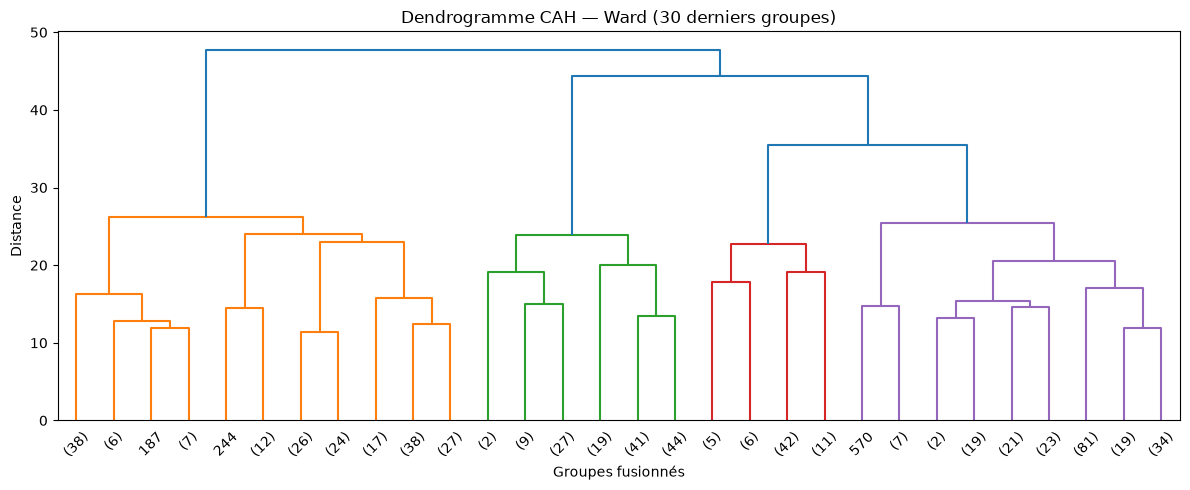

DBSCAN retenu : eps=3.7711, min_samples=4
Clusters DBSCAN hors bruit : 2
Part de bruit : 6.6%


,eps,min_samples,clusters,coverage,silhouette,selection_score
0,3.771057,4,2,0.934426,0.30401,0.284075


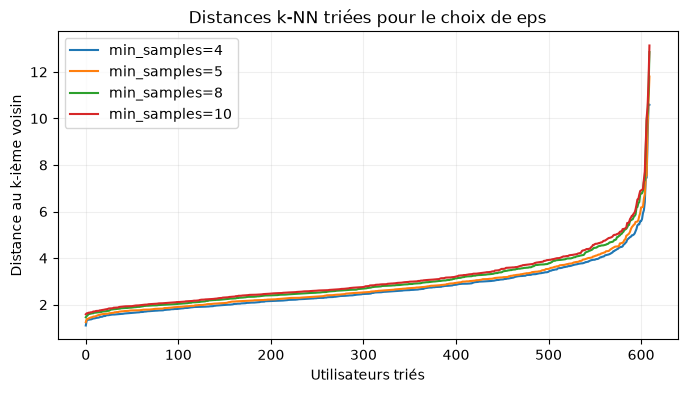

In [23]:
hierarchy = linkage(X_scaled, method='ward')
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(hierarchy, truncate_mode='lastp', p=30, show_leaf_counts=True, ax=ax)
ax.set(title='Dendrogramme CAH — Ward (30 derniers groupes)', xlabel='Groupes fusionnés', ylabel='Distance')
plt.tight_layout()
plt.show()

from sklearn.cluster import AgglomerativeClustering
hierarchical_labels = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X_scaled)

dbscan_model, dbscan_candidates, distance_curves = fit_dbscan(X_scaled)
dbscan_labels = dbscan_model.labels_
print(f'DBSCAN retenu : eps={dbscan_model.eps:.4f}, min_samples={dbscan_model.min_samples}')
print(f'Clusters DBSCAN hors bruit : {len(set(dbscan_labels) - {-1})}')
print(f'Part de bruit : {(dbscan_labels == -1).mean():.1%}')
if dbscan_candidates.empty:
    print('Aucun réglage testé ne forme au moins deux clusters évaluables ; paramètres de repli affichés ci-dessus.')
else:
    display(dbscan_candidates.sort_values('selection_score', ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8, 4))
for min_samples, distances in distance_curves.items():
    ax.plot(np.arange(len(distances)), distances, label=f'min_samples={min_samples}')
ax.set(title='Distances k-NN triées pour le choix de eps', xlabel='Utilisateurs triés', ylabel='Distance au k-ième voisin')
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## Comparaison et profils métier

La silhouette DBSCAN est calculée uniquement sur les utilisateurs non-bruit ; la proportion de bruit est indiquée séparément. Les profils donnent les genres dominants, la note moyenne et le nombre moyen de films notés par utilisateur.

,algorithm,clusters_excluding_noise,noise_share,silhouette_excluding_noise
2,DBSCAN,2,0.065574,0.304010
0,K-Means,2,0.000000,0.124772
1,CAH (Ward),2,0.000000,0.101968


,algorithm,cluster,business_name,users,top_genres,mean_rating,mean_ratings_per_user
0,CAH (Ward),0,"Cinéphiles grand public — Comedy, Drama, Action",413,"Comedy, Drama, Action",3.64,174.8
1,CAH (Ward),1,"Cinéphiles grand public — Drama, Comedy, Thriller",197,"Drama, Comedy, Thriller",3.70,145.5
2,DBSCAN,-1,Profils atypiques (bruit DBSCAN),40,"Drama, Comedy, Adventure",3.73,52.1
3,DBSCAN,0,"Cinéphiles grand public — Drama, Comedy, Action",567,"Drama, Comedy, Action",3.65,173.9
4,DBSCAN,1,"Micro-segment à investiguer — Horror, Comedy, ...",3,"Horror, Comedy, Drama",4.00,44.3
5,K-Means,0,"Cinéphiles grand public — Drama, Comedy, Thriller",355,"Drama, Comedy, Thriller",3.61,180.0
6,K-Means,1,"Cinéphiles grand public — Drama, Action, Comedy",255,"Drama, Action, Comedy",3.72,144.9


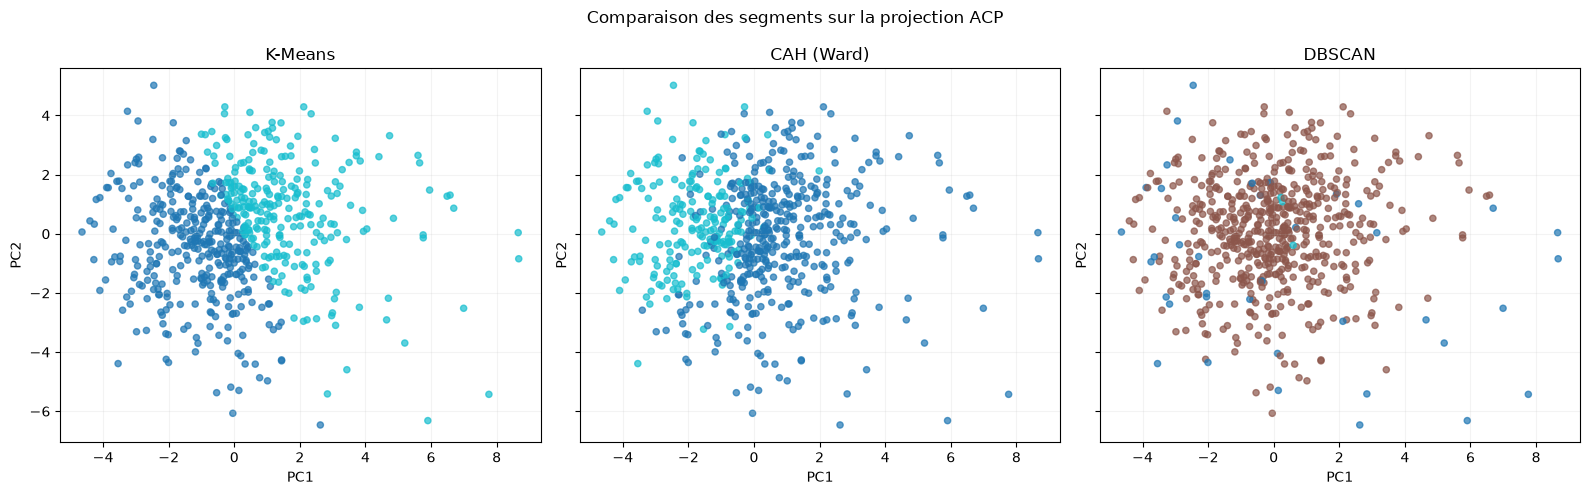

In [24]:
label_sets = {
    'K-Means': kmeans_labels,
    'CAH (Ward)': hierarchical_labels,
    'DBSCAN': dbscan_labels,
}
comparison = compare_clusterings(X_scaled, label_sets)
profiles = profile_segments(user_genre_matrix, ratings, label_sets)
display(comparison.sort_values('silhouette_excluding_noise', ascending=False, na_position='last'))
display(profiles.sort_values(['algorithm', 'cluster']).reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (algorithm, labels) in zip(axes, label_sets.items()):
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=20, alpha=0.7)
    ax.set(title=algorithm, xlabel='PC1', ylabel='PC2')
    ax.grid(alpha=0.15)
fig.suptitle('Comparaison des segments sur la projection ACP')
plt.tight_layout()
plt.show()

## Bonus — regrouper les films

K-Means regroupe les films à partir de leurs genres (indicateurs binaires). Les exemples et genres dominants permettent d’interpréter rapidement les groupes.

In [25]:
movie_clusters, movie_profiles = cluster_movies(movies, n_clusters=8)
display(movie_profiles)

,cluster,movies,top_genres,example_titles
0,0,796,"Action, Adventure, Sci-Fi",GoldenEye (1995) | Cutthroat Island (1995) | C...
1,1,965,"Comedy, Drama, Romance","Waiting to Exhale (1995) | American President,..."
2,2,788,"Horror, Thriller, Sci-Fi",From Dusk Till Dawn (1996) | Mary Reilly (1996...
3,3,1158,"Thriller, Drama, Crime",Heat (1995) | Money Train (1995) | Get Shorty ...
4,4,2285,"Comedy, Romance, Action",Grumpier Old Men (1995) | Father of the Bride ...
5,5,2418,"Drama, Romance, Crime",Nixon (1995) | Casino (1995) | Sense and Sensi...
6,6,800,"Documentary, Action, Crime",Sudden Death (1995) | Fair Game (1995) | Nico ...
7,7,532,"Children, Animation, Adventure",Toy Story (1995) | Jumanji (1995) | Tom and Hu...
